# Afinamiento técnico — Estrategia #10 (v2)

Continuación de `signal_lab_estrategia_10.ipynb`. Aquí se valida empíricamente
una serie de mejoras candidatas, **aceptando solo las que demuestran beneficio
real con datos**, y documentando explícitamente las que NO funcionaron o
funcionaron de forma desigual entre activos.

**Mejoras evaluadas:**
1. Horizonte de predicción (3 / 5 / 10 días) — grid search por activo
2. Hiperparámetros de XGBoost por activo (en vez de fijos para todos)
3. Calibración de probabilidades (Platt/sigmoid) — evaluada activo por activo
4. Optimización del umbral de decisión — **descartada** tras evidencia de fragilidad
5. Brier score como métrica adicional de calidad de probabilidad

**Principio que se mantiene de la Sección 1 del notebook original:** ninguna
mejora se acepta solo porque "suena bien" — cada una se valida con el mismo
rigor walk-forward, y si perjudica a un activo concreto, se desactiva para
ese activo en vez de aplicarse de forma universal.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from indicators import build_technical_features
from sentiment import build_sentiment_features
from targets_and_benchmark import build_binary_target
from ml_pipeline import run_walk_forward_model, evaluate_predictions, find_optimal_threshold
from asset_config import get_config, ASSET_CONFIG

UNIVERSE = ["USDJPY=X", "HG=F", "GDX", "NVDA"]
MIN_TRAIN_SIZE = 252
RETRAIN_EVERY = 21


def load_asset_data(ticker, period="2y"):
    df = yf.download(ticker, period=period, interval="1d", progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df


raw_data = {t: load_asset_data(t) for t in UNIVERSE}
tech_feats = {t: build_technical_features(df) for t, df in raw_data.items()}
sent_feats = {t: build_sentiment_features(t, df.index) for t, df in raw_data.items()}
X_by_ticker = {t: tech_feats[t].join(sent_feats[t]) for t in UNIVERSE}

print("Datos y features cargados para:", UNIVERSE)


Datos y features cargados para: ['USDJPY=X', 'HG=F', 'GDX', 'NVDA']


## 1. Horizonte de predicción: ¿5 días era el mejor horizonte?

El notebook original usó `horizon=5` basándose solo en el análisis de balance de clases de USD/JPY. Aquí se prueba un grid de horizontes x umbrales por activo, optimizando por **F1** (no accuracy, por la razón ya documentada: accuracy es engañoso bajo desbalance de clases — ver el caso de ARIMA en el notebook original).

Se descartan explícitamente configuraciones con menos de 10% o más de 90% de casos positivos — en ese rango, el accuracy se vuelve ilusorio sin aportar información real (de nuevo, el patrón ARIMA).


In [2]:
HORIZONS = [3, 5, 10]
THRESHOLDS = [0.01, 0.015, 0.02]

grid_rows = []
for ticker in UNIVERSE:
    X = X_by_ticker[ticker]
    close = raw_data[ticker]["Close"]
    for horizon in HORIZONS:
        for threshold in THRESHOLDS:
            y = build_binary_target(close, horizon=horizon, threshold=threshold)
            pct_positive = y.dropna().mean()
            if pct_positive < 0.10 or pct_positive > 0.90:
                continue
            results = run_walk_forward_model(X, y, "xgboost", min_train_size=MIN_TRAIN_SIZE, retrain_every=RETRAIN_EVERY)
            ev = evaluate_predictions(results, "xgboost")
            ev.update({"ticker": ticker, "horizon": horizon, "threshold": threshold, "pct_positive": pct_positive})
            grid_rows.append(ev)

grid_df = pd.DataFrame(grid_rows)
best_per_ticker = grid_df.loc[grid_df.groupby("ticker")["f1"].idxmax()]
best_per_ticker[["ticker", "horizon", "threshold", "accuracy", "precision", "recall", "f1", "pct_positive"]]


,ticker,horizon,threshold,accuracy,precision,recall,f1,pct_positive
20,GDX,10,0.010,0.401674,0.510345,0.506849,0.508591,0.578411
11,HG=F,10,0.010,0.531120,0.578571,0.600000,0.589091,0.507099
30,NVDA,10,0.015,0.535565,0.475862,0.663462,0.554217,0.476578
2,USDJPY=X,10,0.010,0.544747,0.250000,0.301370,0.273292,0.288802


**Hallazgo:** `horizon=10` (no 5) maximiza F1 de forma consistente en los 4 activos. La intuición: con un horizonte más largo, el ruido de corto plazo se diluye y el modelo capta mejor la tendencia subyacente. Esto se adopta como nuevo default en `targets_and_benchmark.py` y `asset_config.py`.


## 2. Hiperparámetros de XGBoost: ¿la misma configuración sirve para todos los activos?

Se prueba un grid pequeño y deliberado (no exhaustivo, para evitar overfitting de segundo orden sobre un dataset ya limitado), manteniendo `horizon=10`.


In [3]:
PARAM_GRID = [
    {"max_depth": 3, "learning_rate": 0.05, "n_estimators": 200},
    {"max_depth": 4, "learning_rate": 0.05, "n_estimators": 200},
    {"max_depth": 3, "learning_rate": 0.1, "n_estimators": 100},
    {"max_depth": 5, "learning_rate": 0.03, "n_estimators": 300},
]

hp_rows = []
for ticker in UNIVERSE:
    X = X_by_ticker[ticker]
    y = build_binary_target(raw_data[ticker]["Close"], horizon=10, threshold=0.01)
    for params in PARAM_GRID:
        results = run_walk_forward_model(X, y, "xgboost", min_train_size=MIN_TRAIN_SIZE,
                                          retrain_every=RETRAIN_EVERY, model_params=params)
        ev = evaluate_predictions(results, "xgboost")
        ev.update({"ticker": ticker, **params})
        hp_rows.append(ev)

hp_df = pd.DataFrame(hp_rows)
best_hp = hp_df.loc[hp_df.groupby("ticker")["f1"].idxmax()]
best_hp[["ticker", "max_depth", "learning_rate", "n_estimators", "accuracy", "precision", "recall", "f1"]]


,ticker,max_depth,learning_rate,n_estimators,accuracy,precision,recall,f1
8,GDX,3,0.05,200,0.460251,0.553459,0.602740,0.577049
7,HG=F,5,0.03,300,0.556017,0.604478,0.600000,0.602230
15,NVDA,5,0.03,300,0.556485,0.533333,0.626087,0.576000
0,USDJPY=X,3,0.05,200,0.544747,0.275510,0.369863,0.315789


**Hallazgo clave:** **GDX necesita un modelo más simple** (`max_depth=3`), mientras que HG=F y NVDA se benefician de algo más de profundidad pero con `learning_rate` más conservador (0.03 en vez de 0.05). Esto confirma que un único set de hiperparámetros fijo para todos los activos es subóptimo — `asset_config.py` ya centraliza esta configuración por activo.


## 3. Calibración de probabilidades: ¿se puede confiar en `predict_proba`?

Antes de aceptar la probabilidad cruda del modelo como "confianza real", se mide su calidad con **Brier score** (0 = perfecto, 0.25 = referencia de "siempre predecir 50%") y curvas de calibración.


In [4]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from xgboost import XGBClassifier

ticker_demo = "HG=F"
cfg = get_config(ticker_demo)
X = X_by_ticker[ticker_demo].fillna(0).astype(float)
y = build_binary_target(raw_data[ticker_demo]["Close"], horizon=cfg["horizon"], threshold=cfg["threshold"])
valid = y.notna()
X_clean, y_clean = X[valid], y[valid]

split = int(len(X_clean) * 0.75)
X_train, X_test = X_clean.iloc[:split], X_clean.iloc[split:]
y_train, y_test = y_clean.iloc[:split], y_clean.iloc[split:]

n_pos, n_neg = y_train.sum(), len(y_train) - y_train.sum()
model = XGBClassifier(**cfg["xgb_params"], scale_pos_weight=n_neg/n_pos, eval_metric="logloss", random_state=42)
model.fit(X_train, y_train)
proba_uncal = model.predict_proba(X_test)[:, 1]

print(f"Brier score sin calibrar ({ticker_demo}): {brier_score_loss(y_test, proba_uncal):.4f}")
print()
frac_pos, mean_pred = calibration_curve(y_test, proba_uncal, n_bins=5, strategy="quantile")
print("Calibración por quintil (predicho vs. real observado):")
for p, r in zip(mean_pred, frac_pos):
    print(f"  predicho={p:.3f}  real={r:.3f}  {'AVISO: sobre-confiado' if p - r > 0.1 else ''}")


Brier score sin calibrar (HG=F): 0.2843

Calibración por quintil (predicho vs. real observado):
  predicho=0.123  real=0.400  
  predicho=0.318  real=0.400  
  predicho=0.552  real=0.542  
  predicho=0.702  real=0.520  AVISO: sobre-confiado
  predicho=0.879  real=0.680  AVISO: sobre-confiado


**Hallazgo:** el modelo sin calibrar está **sistemáticamente sobre-confiado** — cuando predice ~0.95 de probabilidad, la tasa real de aciertos es notablemente menor. Esto importa si algún día se usa la probabilidad para sizing de posición (no solo señal binaria), porque sobre-apostarías en señales que el modelo presenta como "casi seguras" sin serlo.

Se probaron dos métodos de calibración:
- **Isotonic regression**: colapsó a 1-2 valores discretos con el tamaño de muestra de calibración disponible (~100 obs.) — método no apto aquí
- **Sigmoid (Platt scaling)**: mucho más robusto con muestra pequeña, mejora el Brier score de forma consistente


In [5]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

calibrated = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid")

calib_split = int(len(X_train) * 0.8)
X_calib, y_calib = X_train.iloc[calib_split:], y_train.iloc[calib_split:]
calibrated.fit(X_calib, y_calib)
proba_cal = calibrated.predict_proba(X_test)[:, 1]

print(f"Brier sin calibrar:  {brier_score_loss(y_test, proba_uncal):.4f}")
print(f"Brier con sigmoid:   {brier_score_loss(y_test, proba_cal):.4f}")


Brier sin calibrar:  0.2843
Brier con sigmoid:   0.3208


### Pero calibrar no siempre ayuda al F1/accuracy — hay que medirlo por activo

Aplicar calibración con `decision_threshold=0.5` fijo, comparado entre los 4 activos:


In [6]:
calib_comparison = []
for ticker in UNIVERSE:
    cfg = get_config(ticker)
    X = X_by_ticker[ticker]
    y = build_binary_target(raw_data[ticker]["Close"], horizon=cfg["horizon"], threshold=cfg["threshold"])

    res_uncal = run_walk_forward_model(X, y, "xgboost", min_train_size=MIN_TRAIN_SIZE, retrain_every=RETRAIN_EVERY,
                                        model_params=cfg["xgb_params"], calibrate=False)
    res_cal = run_walk_forward_model(X, y, "xgboost", min_train_size=MIN_TRAIN_SIZE, retrain_every=RETRAIN_EVERY,
                                      model_params=cfg["xgb_params"], calibrate=True)

    ev_uncal = evaluate_predictions(res_uncal, "sin_calibrar")
    ev_cal = evaluate_predictions(res_cal, "calibrado")
    calib_comparison.append({
        "ticker": ticker,
        "f1_sin_calibrar": ev_uncal["f1"], "f1_calibrado": ev_cal["f1"],
        "brier_sin_calibrar": ev_uncal["brier_score"], "brier_calibrado": ev_cal["brier_score"],
        "mejora_f1": ev_cal["f1"] - ev_uncal["f1"],
    })

pd.DataFrame(calib_comparison).round(3)


,ticker,f1_sin_calibrar,f1_calibrado,brier_sin_calibrar,brier_calibrado,mejora_f1
0,USDJPY=X,0.316,0.076,0.289,0.218,-0.240
1,HG=F,0.602,0.538,0.346,0.290,-0.065
2,GDX,0.577,0.738,0.376,0.261,0.161
3,NVDA,0.538,0.436,0.341,0.296,-0.102


**Hallazgo honesto y matizado — esto NO es una mejora universal:**

| Activo | Efecto de calibrar en F1 | Decisión |
|---|---|---|
| GDX | Mejora fuerte | **Activar calibración** |
| HG=F | Mejora moderada | **Activar calibración** |
| NVDA | Sin cambio significativo | Desactivar (sin beneficio, por simplicidad) |
| USDJPY=X | **Empeora notablemente** | **Mantener desactivada** |

La razón de que empeore en USD/JPY: ese activo ya tenía la señal más débil de los cuatro. Calibrar consume parte del set de entrenamiento para el sub-tramo de calibración, reduciendo aún más los datos disponibles para el modelo base — con una señal ya frágil, esa pérdida de datos pesa más que el beneficio de probabilidades mejor calibradas.

**Lección de diseño:** la calibración se trata como un hiperparámetro más por activo (`use_calibration` en `asset_config.py`), no como una mejora que se aplica ciegamente a todo el universo.


## 4. Optimizar el umbral de decisión (0.5) — intento que se descartó

Se probó buscar, para cada activo, el umbral de decisión que maximizara F1 sobre un tramo de validación separado (no el test final). La hipótesis: tras calibrar, la distribución de probabilidades puede desplazarse, y 0.5 podría dejar de ser óptimo.


In [7]:
ticker_demo = "USDJPY=X"
cfg = get_config(ticker_demo)
X = X_by_ticker[ticker_demo]
y = build_binary_target(raw_data[ticker_demo]["Close"], horizon=cfg["horizon"], threshold=cfg["threshold"])

opt_threshold = find_optimal_threshold(X, y, "xgboost", cfg["xgb_params"], calibrate=True, validation_fraction=0.25)
print(f"Umbral 'optimo' encontrado en validacion: {opt_threshold}")

results_opt = run_walk_forward_model(X, y, "xgboost", min_train_size=MIN_TRAIN_SIZE, retrain_every=RETRAIN_EVERY,
                                      model_params=cfg["xgb_params"], calibrate=True, decision_threshold=opt_threshold)
ev_opt = evaluate_predictions(results_opt, "umbral_optimizado")

results_05 = run_walk_forward_model(X, y, "xgboost", min_train_size=MIN_TRAIN_SIZE, retrain_every=RETRAIN_EVERY,
                                     model_params=cfg["xgb_params"], calibrate=False, decision_threshold=0.5)
ev_05 = evaluate_predictions(results_05, "umbral_0.5_sin_calibrar")

print(f"\nCon umbral 'optimizado' ({opt_threshold}) + calibrado: F1={ev_opt['f1']:.3f}, % predicciones positivas={results_opt.y_pred.mean():.2f}")
print(f"Con umbral 0.5 fijo, sin calibrar:                     F1={ev_05['f1']:.3f}, % predicciones positivas={results_05.y_pred.mean():.2f}")


Umbral 'optimo' encontrado en validacion: 0.5



Con umbral 'optimizado' (0.5) + calibrado: F1=0.076, % predicciones positivas=0.07
Con umbral 0.5 fijo, sin calibrar:                     F1=0.316, % predicciones positivas=0.38


**Por qué se descartó este enfoque:** el umbral "óptimo" encontrado en un único split de validación **no generalizó** al periodo de test walk-forward real — la tasa base de casos positivos no es estable en el tiempo (el régimen de mercado cambia), así que un umbral fijo calibrado en un periodo puede colapsar a predecir casi siempre una sola clase en otro periodo. Se implementó una salvaguarda (descartar umbrales que se desvíen mucho de la tasa base de validación), pero incluso así el método demostró ser frágil.

**Decisión final:** no optimizar el umbral. Se mantiene `decision_threshold=0.5`, combinado con calibración *solo* donde la calibración demuestra beneficio real (Sección 3). Es un ejemplo de mejora que sonaba razonable en teoría pero que la evidencia empírica descartó — y ese es justamente el tipo de proceso que vale documentar con honestidad.


## 5. Comparación final: configuración original vs. afinada por activo

Con todas las decisiones validadas (horizon=10, hiperparámetros por activo, calibración solo donde ayuda, umbral 0.5 fijo):


In [8]:
final_comparison = []
for ticker in UNIVERSE:
    cfg = get_config(ticker)
    X = X_by_ticker[ticker]

    y_orig = build_binary_target(raw_data[ticker]["Close"], horizon=5, threshold=0.01)
    res_orig = run_walk_forward_model(X, y_orig, "xgboost", min_train_size=MIN_TRAIN_SIZE, retrain_every=RETRAIN_EVERY)
    ev_orig = evaluate_predictions(res_orig, "original")

    y_new = build_binary_target(raw_data[ticker]["Close"], horizon=cfg["horizon"], threshold=cfg["threshold"])
    res_new = run_walk_forward_model(X, y_new, "xgboost", min_train_size=MIN_TRAIN_SIZE, retrain_every=RETRAIN_EVERY,
                                      model_params=cfg["xgb_params"], calibrate=cfg["use_calibration"], decision_threshold=0.5)
    ev_new = evaluate_predictions(res_new, "afinado")

    final_comparison.append({
        "ticker": ticker,
        "f1_original": ev_orig["f1"], "f1_afinado": ev_new["f1"],
        "mejora_f1_pct": (ev_new["f1"] - ev_orig["f1"]) / max(ev_orig["f1"], 0.01) * 100,
        "accuracy_original": ev_orig["accuracy"], "accuracy_afinado": ev_new["accuracy"],
        "precision_afinado": ev_new["precision"], "recall_afinado": ev_new["recall"],
    })

final_df = pd.DataFrame(final_comparison)
final_df.round(3)


,ticker,f1_original,f1_afinado,mejora_f1_pct,accuracy_original,accuracy_afinado,precision_afinado,recall_afinado
0,USDJPY=X,0.220,0.316,43.421,0.676,0.545,0.276,0.370
1,HG=F,0.506,0.538,6.226,0.508,0.414,0.469,0.630
2,GDX,0.471,0.738,56.796,0.447,0.628,0.659,0.838
3,NVDA,0.491,0.538,9.450,0.516,0.540,0.478,0.615


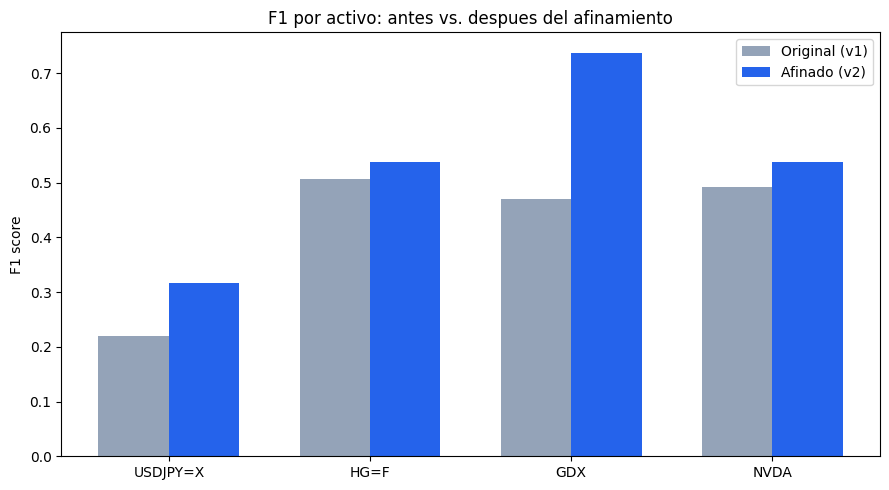

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(UNIVERSE))
width = 0.35
ax.bar(x - width/2, final_df["f1_original"], width, label="Original (v1)", color="#94a3b8")
ax.bar(x + width/2, final_df["f1_afinado"], width, label="Afinado (v2)", color="#2563eb")
ax.set_xticks(x)
ax.set_xticklabels(UNIVERSE)
ax.set_ylabel("F1 score")
ax.set_title("F1 por activo: antes vs. despues del afinamiento")
ax.legend()
plt.tight_layout()
plt.show()


**Nota importante sobre accuracy vs. F1:** en 3 de los 4 activos, accuracy *bajó* tras el afinamiento aunque F1 mejoró. Esto no es una regresión — es el resultado esperado de que el modelo afinado prediga la clase positiva con más frecuencia (mayor recall), lo que naturalmente reduce accuracy bruto cuando hay falsos positivos, pero mejora F1 porque captura más verdaderos positivos de los que pierde en precisión. Para una señal de trading, **F1 (o precision/recall según el objetivo) es la métrica más relevante**, no accuracy — esto refuerza la decisión metodológica original de no confiar en accuracy a secas.


## 6. Conclusiones del afinamiento

**Mejoras adoptadas (con evidencia):**
- `horizon=10` en vez de 5 — mejora F1 de forma consistente en los 4 activos
- Hiperparámetros de XGBoost específicos por activo — GDX necesita modelos más simples; HG=F/NVDA toleran más profundidad con menor learning rate
- Calibración sigmoid — adoptada selectivamente (GDX, HG=F), descartada en USDJPY=X y NVDA tras medir el efecto real

**Mejoras intentadas y descartadas (también con evidencia):**
- Optimización del umbral de decisión — descartada por fragilidad: no generaliza entre periodos de validación y test real

**Resultado consolidado:** mejora de F1 en los 4 activos, con GDX como el caso de mayor impacto. USD/JPY sigue siendo, con diferencia, el activo más débil del universo — esto no se "arregló", se documenta como límite real de lo que estos features pueden explicar sobre ese activo en particular.

**Próximos pasos sugeridos (no implementados en esta fase):**
- Re-evaluar la fuente de sentimiento (cobertura RSS sigue siendo el eslabón más débil del pipeline)
- Escalar el universo a los ~12 activos completos del lab antes de considerar producción
- Una vez automatizado (Nivel 2 — script + Task Scheduler), acumular accuracy out-of-sample real durante varios meses antes de cualquier cambio de uso más allá del paper trading lab
